# Lab 03-02 · Random Variables and Distributions

Companion to chapter [03-02](../../chapters/03-02-random-variables-and-distributions.md). Handout: [README.md](README.md).

Each part draws random samples and compares what they show with the chapter's PMFs, PDFs and tail formulas. Cells marked **🔮 Predict** ask you to write a prediction *before* running. The seed is fixed, so your numbers will match the handout's.

In [1]:
import math, sys
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.integrate import quad
from scipy.optimize import brentq
sys.path.insert(0, str(Path.cwd().parents[3] / "tools"))
try:
    from plotstyle import use_style; use_style()
except ImportError:
    pass
rng = np.random.default_rng(2026)
Q, Qinv = stats.norm.sf, stats.norm.isf

## Part 1 — Histograms become distributions

Draw samples of four random variables and overlay the theory: binomial ($n = 20$, $p = 0.05$, Problem 03-02.3), Poisson (λ = 1.2, Example 03-02.3), exponential (mean 1000 h) and standard Gaussian.

**🔮 Predict:** how many Gaussian samples do you need to expect 100 of them beyond ±3σ? Beyond ±5σ?

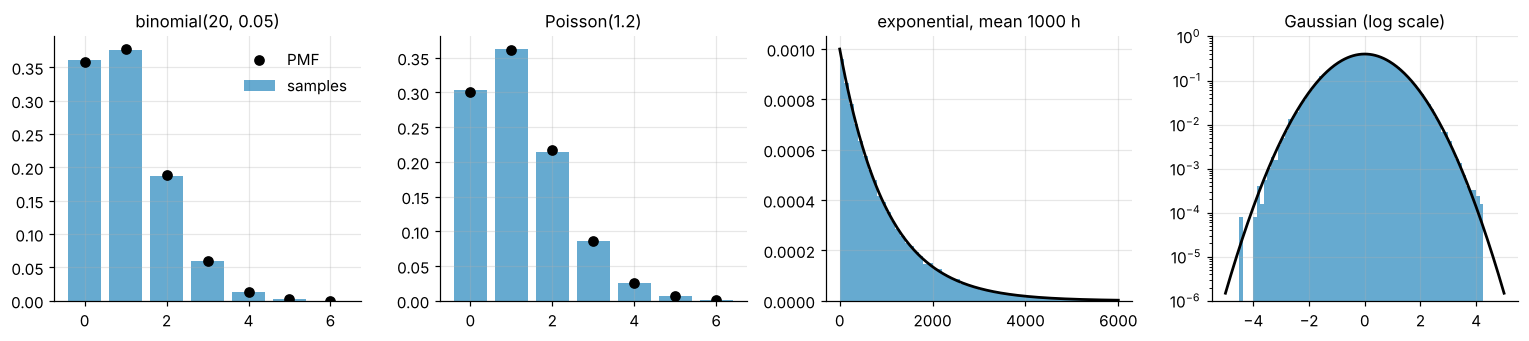

beyond ±3σ: measured 2.65e-03  theory 2Q(3) = 2.700e-03  -> samples for 100 such events: 3.704e+04
beyond ±5σ: measured 0.00e+00  theory 2Q(5) = 5.733e-07  -> samples for 100 such events: 1.744e+08


In [2]:
N = 100_000
fig, ax = plt.subplots(1, 4, figsize=(14, 3.2))
x = rng.binomial(20, 0.05, N); k = np.arange(0, 7)
ax[0].bar(k, np.bincount(x, minlength=7)[:7] / N, color="C0", alpha=0.6, label="samples")
ax[0].plot(k, stats.binom.pmf(k, 20, 0.05), "ko", label="PMF"); ax[0].set_title("binomial(20, 0.05)"); ax[0].legend()
x = rng.poisson(1.2, N)
ax[1].bar(k, np.bincount(x, minlength=7)[:7] / N, color="C0", alpha=0.6)
ax[1].plot(k, stats.poisson.pmf(k, 1.2), "ko"); ax[1].set_title("Poisson(1.2)")
x = rng.exponential(1000, N); t = np.linspace(0, 6000, 200)
ax[2].hist(x, bins=60, range=(0, 6000), density=True, color="C0", alpha=0.6)
ax[2].plot(t, np.exp(-t / 1000) / 1000, "k"); ax[2].set_title("exponential, mean 1000 h")
z = rng.standard_normal(N); zz = np.linspace(-5, 5, 300)
ax[3].hist(z, bins=80, range=(-5, 5), density=True, color="C0", alpha=0.6)
ax[3].semilogy(zz, stats.norm.pdf(zz), "k"); ax[3].set_ylim(1e-6, 1); ax[3].set_title("Gaussian (log scale)")
fig.tight_layout(); plt.show()
for kk in (3, 5):
    print(f"beyond ±{kk}σ: measured {np.mean(np.abs(z) > kk):.2e}  theory 2Q({kk}) = {2 * Q(kk):.3e}"
          f"  -> samples for 100 such events: {100 / (2 * Q(kk)):.4g}")

With $10^5$ samples the ±3σ fraction is measured to within a few percent, but the ±5σ fraction rests on a few events or none. On the log-scale panel, the histogram stops well before the density does: **sampling cannot show you a tail that is rarer than one over the sample count.** That is why BER at $10^{-12}$ is extrapolated from a model, not measured directly (Part 6).

## Part 2 — The Poisson limit

Hold λ = $np$ = 1.2 fixed and let $n$ grow. Measure the distance between the binomial and Poisson PMFs by the **total variation distance** $\tfrac12\sum_k|p_{\text{bin}}(k) - p_{\text{Poi}}(k)|$, the largest difference in probability the two models can assign to any event. Le Cam's inequality bounds it by $np^2 = \lambda^2/n$.

**🔮 Predict:** by what factor does the distance shrink each time $n$ grows tenfold?

In [3]:
lam = 1.2
for n in (12, 120, 1200, 12_000):
    k = np.arange(0, n + 1)
    tv = 0.5 * np.sum(np.abs(stats.binom.pmf(k, n, lam / n) - stats.poisson.pmf(k, lam)))
    tv += 0.5 * stats.poisson.sf(n, lam)           # Poisson mass above n, where the binomial has none
    print(f"n = {n:>6}: total variation {tv:.3e}   Le Cam bound lam^2/n = {lam**2 / n:.3e}")

n =     12: total variation 2.841e-02   Le Cam bound lam^2/n = 1.200e-01
n =    120: total variation 2.690e-03   Le Cam bound lam^2/n = 1.200e-02
n =   1200: total variation 2.676e-04   Le Cam bound lam^2/n = 1.200e-03
n =  12000: total variation 2.675e-05   Le Cam bound lam^2/n = 1.200e-04


The distance falls tenfold per decade of $n$, as the bound says. In Example 03-02.3 ($n$ = 12,000) the two models differ by less than $3\times10^{-5}$ in any probability: far below anything that matters.

## Part 3 — A Poisson process

Generate events at a constant rate of 2 per unit time for 50,000 time units by summing exponential gaps. Then count events in unit windows.

**🔮 Predict:** what fraction of unit windows contain no event? What are the mean and variance of the count?

events: 100306   mean gap 0.4985 (theory 0.5)
count per window: mean 2.0061, variance 2.0136 (Poisson: both 2.0)
empty windows: 0.1333   theory e^-2 = 0.1353


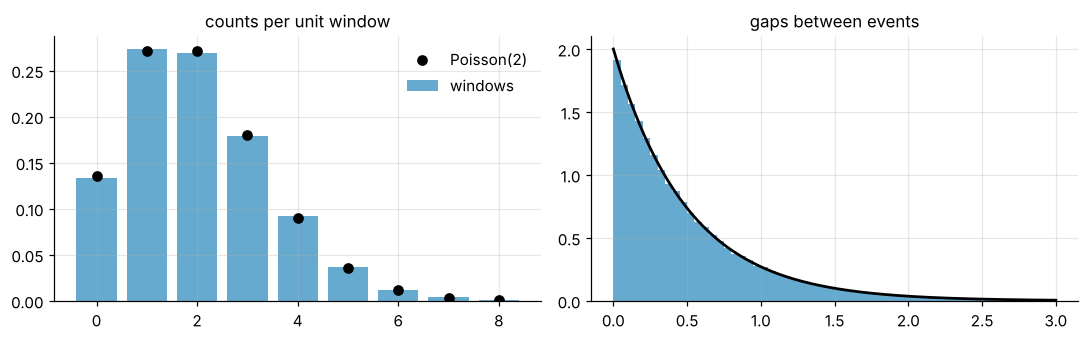

In [4]:
rate, T = 2.0, 50_000
gaps = rng.exponential(1 / rate, int(rate * T * 1.1))
times = np.cumsum(gaps); times = times[times < T]
counts = np.bincount(times.astype(int), minlength=T)[:T]
print(f"events: {times.size}   mean gap {np.mean(np.diff(times)):.4f} (theory {1 / rate})")
print(f"count per window: mean {counts.mean():.4f}, variance {counts.var():.4f} (Poisson: both {rate})")
print(f"empty windows: {np.mean(counts == 0):.4f}   theory e^-2 = {math.exp(-rate):.4f}")
k = np.arange(0, 9)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].bar(k, np.bincount(counts, minlength=9)[:9] / T, color="C0", alpha=0.6, label="windows")
ax[0].plot(k, stats.poisson.pmf(k, rate), "ko", label="Poisson(2)"); ax[0].legend(); ax[0].set_title("counts per unit window")
ax[1].hist(np.diff(times), bins=60, range=(0, 3), density=True, color="C0", alpha=0.6)
tt = np.linspace(0, 3, 200); ax[1].plot(tt, rate * np.exp(-rate * tt), "k"); ax[1].set_title("gaps between events")
fig.tight_layout(); plt.show()

Exponential gaps produce Poisson counts, and the count's variance equals its mean. **A measured variance well above the mean ("overdispersion") is a signature of clustering**, for example defects that arrive in bursts, and a warning that the Poisson model will understate the bad cases.

## Part 4 — Memorylessness, and its opposite

Draw lifetimes with mean 1000 h from two models: exponential (constant failure rate) and Weibull with shape 3 (wear-out; the Weibull is developed in 03-05). Keep the units that survive 500 h and measure their *remaining* life.

**🔮 Predict:** for each model, is the mean remaining life of a 500 h survivor longer than, equal to, or shorter than 1000 h?

In [5]:
N = 400_000
expo = rng.exponential(1000, N)
eta = 1000 / math.gamma(1 + 1 / 3)                  # Weibull scale giving a mean of 1000 h
weib = eta * rng.weibull(3, N)
for name, life in (("exponential", expo), ("Weibull k = 3", weib)):
    rem = life[life > 500] - 500
    print(f"{name:14s}: survivors {np.mean(life > 500):.4f}   mean remaining life {rem.mean():7.1f} h")
S = lambda t: math.exp(-(t / eta) ** 3)
mrl = quad(S, 500, np.inf)[0] / S(500)
print(f"Weibull theory: mean remaining life after 500 h = {mrl:.1f} h")

exponential   : survivors 0.6058   mean remaining life   998.2 h


Weibull k = 3 : survivors 0.9146   mean remaining life   559.4 h
Weibull theory: mean remaining life after 500 h = 558.4 h


The exponential survivor is "as good as new": its remaining life is still 1000 h on average. The wear-out survivor has used up life: its remaining mean is about 558 h. Constant-rate FIT arithmetic is valid only on the flat floor of the bathtub, never in wear-out.

## Part 5 — BER by Monte Carlo

Send random bits as ±A in Gaussian noise, slice at zero, and count errors.

**🔮 Predict:** at $A/\sigma = 4$, how many bits must you send to see about 100 errors?

In [6]:
def mc_ber(snr, nbits, chunk=2_000_000):
    errs = 0
    for start in range(0, nbits, chunk):
        m = min(chunk, nbits - start)
        bits = rng.integers(0, 2, m)
        rx = (2 * bits - 1) * snr + rng.standard_normal(m)   # sigma = 1
        errs += np.count_nonzero((rx > 0) != (bits == 1))
    return errs
for snr, nbits in ((2, 200_000), (3, 2_000_000), (4, 6_000_000)):
    e = mc_ber(snr, nbits)
    print(f"A/sigma = {snr}: {e} errors in {nbits:.1e} bits -> BER {e / nbits:.3e}"
          f"   Q(A/sigma) = {Q(snr):.3e}   expected errors {nbits * Q(snr):.0f}")
print(f"bits for 100 errors at A/sigma = 4: {100 / Q(4):.4g}")

A/sigma = 2: 4584 errors in 2.0e+05 bits -> BER 2.292e-02   Q(A/sigma) = 2.275e-02   expected errors 4550
A/sigma = 3: 2654 errors in 2.0e+06 bits -> BER 1.327e-03   Q(A/sigma) = 1.350e-03   expected errors 2700
A/sigma = 4: 179 errors in 6.0e+06 bits -> BER 2.983e-05   Q(A/sigma) = 3.167e-05   expected errors 190
bits for 100 errors at A/sigma = 4: 3.157e+06


The measured BER agrees with $Q(A/\sigma)$ within the Poisson scatter of the error count (about $\pm\sqrt{\text{count}}$). At $A/\sigma = 7.034$ the same experiment would need $10^{14}$ bits for 100 errors, which is why Part 6 relies on a model.

## Part 6 — Dual-Dirac jitter and the bathtub

Model the crossing time of an eye edge as two Diracs at ±DJ/2 blurred by Gaussian RJ, with Example 03-02.7's values: 32 GT/s (UI = 31.25 ps), DJ = 8 ps, RJ = 1.2 ps rms.

**🔮 Predict:** beyond $DJ/2 + 3\sigma$ from the edge's center, what fraction of crossings lands? Does the far Dirac contribute?

crossings beyond DJ/2 + 3 sigma: measured 6.710e-04
  near Dirac 0.5 Q(3) = 6.749e-04   far Dirac 0.5 Q(3 + DJ/RJ) = 1.0e-22
convention: eye at 1e-12 from the bathtub 6.367 ps   1 UI - TJ = 6.367 ps
literal model: eye at 1e-12 6.837 ps   multiplier 2 Qinv(4e-12) = 13.677


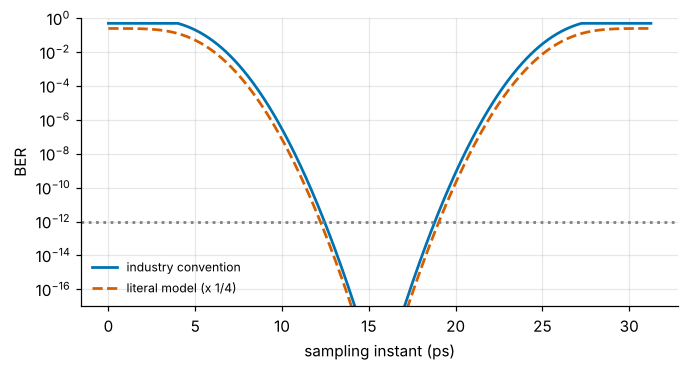

In [7]:
UI, DJ, RJ = 31.25, 8.0, 1.2
N = 4_000_000
cross = rng.choice([-DJ / 2, DJ / 2], N) + RJ * rng.standard_normal(N)
d = DJ / 2 + 3 * RJ
print(f"crossings beyond DJ/2 + 3 sigma: measured {np.mean(cross > d):.3e}")
print(f"  near Dirac 0.5 Q(3) = {0.5 * Q(3):.3e}   far Dirac 0.5 Q(3 + DJ/RJ) = {0.5 * Q(3 + DJ / RJ):.1e}")

# industry Q-scale convention (the chapter's TJ formula): BER(t) = Q((t - DJ/2)/RJ) + Q((UI - t - DJ/2)/RJ)
ber = lambda t: Q((t - DJ / 2) / RJ) + Q((UI - t - DJ / 2) / RJ)
# literal model: a transition (density 1/2) whose edge (Dirac weight 1/2) lands past the sampling instant
ber_lit = lambda t: 0.5 * 0.5 * (Q((t - DJ / 2) / RJ) + Q((UI - t - DJ / 2) / RJ))

def eye(f):
    left = brentq(lambda t: math.log(f(t)) - math.log(1e-12), DJ / 2, UI / 2)
    right = brentq(lambda t: math.log(f(t)) - math.log(1e-12), UI / 2, UI - DJ / 2)
    return right - left

TJ = DJ + 2 * Qinv(1e-12) * RJ
print(f"convention: eye at 1e-12 from the bathtub {eye(ber):.3f} ps   1 UI - TJ = {UI - TJ:.3f} ps")
print(f"literal model: eye at 1e-12 {eye(ber_lit):.3f} ps   multiplier 2 Qinv(4e-12) = {2 * Qinv(4e-12):.3f}")
t = np.linspace(0, UI, 1000)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.semilogy(t, np.clip(ber(t), 1e-18, 0.5), label="industry convention")
ax.semilogy(t, np.clip(ber_lit(t), 1e-18, 0.5), "--", label="literal model (x 1/4)")
ax.axhline(1e-12, color="0.5", ls=":"); ax.legend(fontsize=8)
ax.set_xlabel("sampling instant (ps)"); ax.set_ylabel("BER"); ax.set_ylim(1e-17, 1); plt.show()

Only the near Dirac matters in the tail: the far one is $DJ/\sigma = 6.7$ standard deviations further out. The root-found eye opening matches $1\,\text{UI} - TJ$ to the third decimal, because at $10^{-12}$ the opposite wall's contribution is negligible. The two curves differ by a constant factor of 4 in BER: the literal model counts only transitions (density ½) and only the near Dirac's half of the edges, the factor $\tfrac12Q(3)$ you just measured; the industry convention drops both factors by defining $Q(Q_{\text{BER}}) = \text{BER}$. On the log scale that shifts each wall by under 0.25 ps, and the convention's eye is the smaller, conservative one.

## Your turn

1. In Part 5, change the slicer threshold to $+0.5\sigma$ at $A/\sigma = 4$ and compare the measured BER with $\tfrac12[Q(3.5) + Q(4.5)]$ (Problem 03-02.13's formula).
2. In Part 6, replace the Gaussian RJ with a Student-t distribution of the same rms value (heavier tails) and redo the root finding numerically. How much eye do you lose at $10^{-12}$? This is the "non-Gaussian tails" warning of section 8 in numbers.